# Collision events in argon gas

This notebook shows the basic gaspin workflow on a short molecular dynamics (MD) trajectory of argon gas. The collision events between the atoms are found and classified, and the fraction of time that the atoms spend in each kind of event is calculated. The mean interaction energy of an atom with its neighbours is then obtained in three ways: from the events, from the radial distribution function (RDF) and from the second virial coefficient.

The trajectory is a Lennard-Jones model of argon ($\sigma = 3.4$ Å, $\varepsilon/k_\text{B} = 120$ K) with 343 atoms at 120 K and the number density of an ideal gas at 5 atm, run for 50 ps and saved every 25 fs. It was generated with `example_data/generate_argon_trajectory.py`.

In [1]:
import MDAnalysis as mda
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const

import gaspin as gs

gs.visualisation.set_plot_style()

## Trajectory

The trajectory is read with MDAnalysis. gaspin uses distances in Å and the time between frames in seconds.

In [2]:
u = mda.Universe('example_data/argon.pdb', 'example_data/argon.xtc')

n_atoms = len(u.atoms)
n_frames = len(u.trajectory)
dt = u.trajectory.dt * 1e-12
volume = np.prod(u.dimensions[:3])

print(f'{n_atoms} atoms, {n_frames} frames of {dt * 1e15:.0f} fs, box volume {volume:.3e} Å^3')

343 atoms, 2000 frames of 25 fs, box volume 1.122e+06 Å^3


## Pair potential and classification parameters

The pair potential $V(R)$ is in kelvin. The collision cutoff $R_\text{c}$ is about twice the distance $R_\text{e}$ of the potential minimum. The well tolerance $\Delta_\text{e}$ defines the potential well $R_\text{e} \pm \Delta_\text{e}$, and the prominence $\Delta_\text{p}$ sets which minima of the distance $R(t)$ of a colliding pair are counted. These are length scales of the gas, so they are chosen for each gas, here in proportion to $R_\text{e}$.

In [3]:
sigma = 3.4
epsilon = 120.0
temperature = 120.0


def pair_potential(r):
    return 4*epsilon*((sigma/r)**12 - (sigma/r)**6)


r_e = 2**(1/6) * sigma
cutoff = 8.0
well_tolerance = 0.65
prominence = 0.2

print(f'R_e = {r_e:.3f} Å')

R_e = 3.816 Å


## Collision events

`find_collisions()` records the neighbours within $R_\text{c}$ of every atom in every frame, `process_collisions()` groups these records into events, and `categorize_collisions()` classifies the events into two-body scattering (TBS), multi-body scattering (MBS), perturbed scattering (PS) and van der Waals (vdW) events.

In [4]:
collisions = gs.find_collisions(u, u.atoms, u.atoms, cutoff)
events = gs.process_collisions(collisions)
categorized = gs.categorize_collisions(events, cutoff, r_e, well_tolerance, prominence)

Categorizing collisions: 100%|██████████| 343/343 [00:02<00:00, 159.54it/s]


`collision_statistics()` gives the lifetime and the number of atoms of each event. The numbers of events in each category are plotted below.

Extracting statistics for vdw: 100%|██████████| 86/86 [00:00<00:00, 157.96it/s]


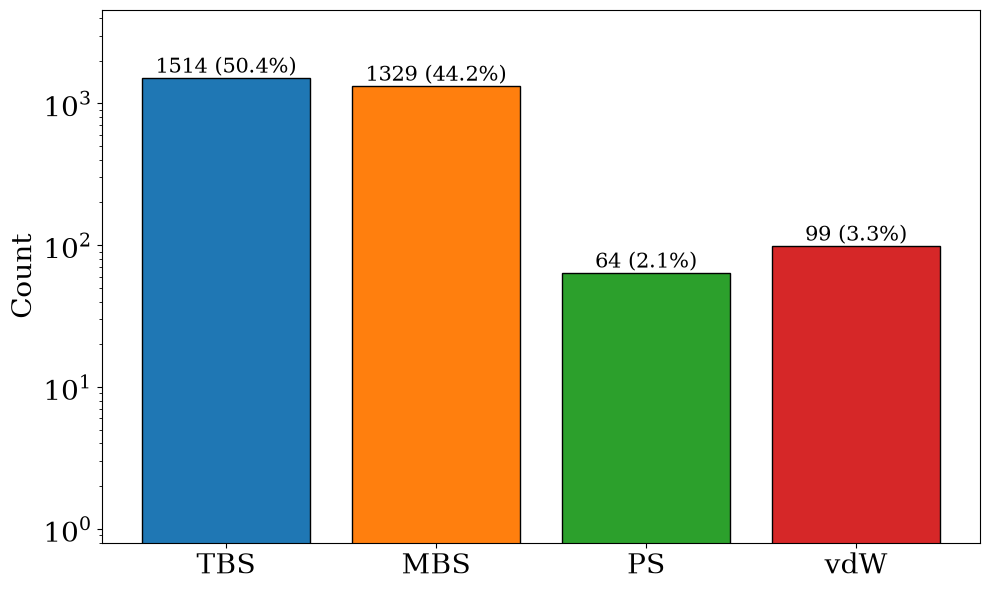

In [5]:
stats, cluster_counts = gs.collision_statistics(categorized, dt, n_frames)
fig = gs.visualisation.plot_collision_counts(gs.collision_counts(stats))

The distance between the atoms of the longest vdW event shows the pair oscillating in the potential well. Other atoms passing by are drawn in colour, and the red line is $R_\text{c}$.

Longest vdW event: 46.3 ps


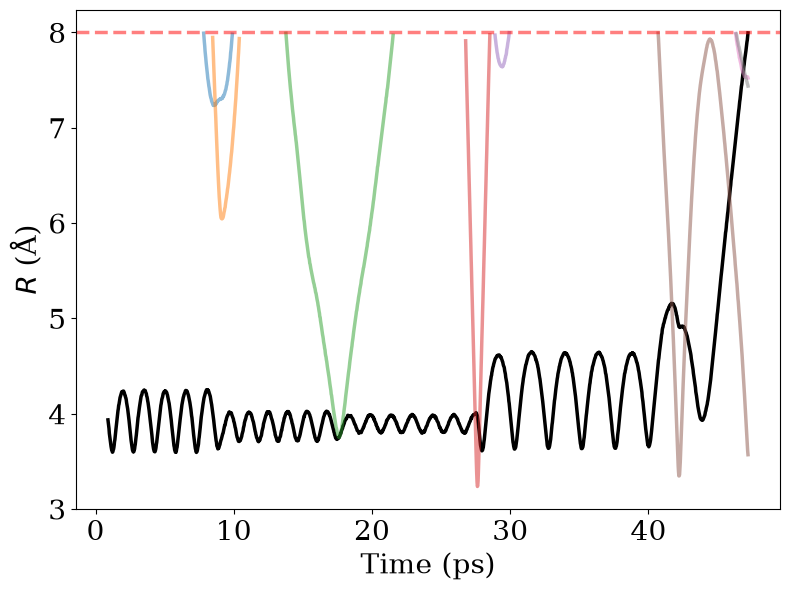

In [6]:
longest = gs.sort_collision_statistics(stats, 'lifetime_ps', atomwise=False)['vdw'][0]
print(f"Longest vdW event: {longest['lifetime_ps']:.1f} ps")

fig = gs.visualisation.plot_distance_series_for_event(categorized, 'vdw', longest['atom_index'],
                                                      longest['event_index'], cutoff, x_axis='time', dt=dt)

## Fractions of time in each category

`atom_time_fractions()` gives the fraction $f_c$ of the total atom-time that the atoms spend in the events of each category $c$. The rest of the time, $f_0$, they are free.

In [7]:
fractions = gs.atom_time_fractions(stats, n_atoms, n_frames, dt)
for category, fraction in fractions.items():
    print(f'{category:24s} {fraction:.4f}')

two_body_scattering      0.1770
multi_body_scattering    0.2171
perturbed_scattering     0.0306
vdw                      0.1080
free_monomers            0.4673


## Mean pair energy of an atom in three ways

The property here is the pair potential itself, so its average is the mean interaction energy of an atom with its neighbours within $R_\text{c}$, $\langle U \rangle$. The same calculation applies to any property that depends only on the distance, such as the nuclear shielding of an atom pair.

**Events.** `average_property_R_time_weighted()` gives the average $\langle U_c \rangle$ of each category, summed over the partners of an atom in each frame. A free atom has no partner, so the mean is $\langle U \rangle = \sum_c f_c \langle U_c \rangle$.

In [8]:
averages = gs.average_property_R_time_weighted(categorized, pair_potential)
U_events = sum(fractions[category] * averages[category]['average_property'] for category in averages)

for category in averages:
    print(f"{category:24s} <U_c> = {averages[category]['average_property']:8.2f} K")
print(f'Events: <U> = {U_events:.3f} K')

Time-weighted averages for vdw: 100%|██████████| 86/86 [00:00<00:00, 778.40it/s]

two_body_scattering      <U_c> =   -22.79 K
multi_body_scattering    <U_c> =   -43.47 K
perturbed_scattering     <U_c> =   -60.58 K
vdw                      <U_c> =   -87.26 K
Events: <U> = -24.747 K


**RDF.** With the partner density $n = (N - 1)/V$, the mean is $\langle U \rangle = n \int_0^{R_\text{c}} V(R)\, g(R)\, 4\pi R^2\, \text{d}R$, from the RDF $g(R)$ of the trajectory.

In [9]:
r, g_r = gs.rdf(u.atoms, u.atoms, nbins=160, range=(0.0, cutoff))
U_rdf = gs.ensemble_average_from_rdf(r, pair_potential(r), g_r, volume, N_other_atoms=n_atoms - 1)
print(f'RDF: <U> = {U_rdf:.3f} K')

RDF: <U> = -24.716 K


**Second virial coefficient.** In the limit of low density, $g(R)$ becomes the Boltzmann factor $\exp[-V(R)/k_\text{B}T]$, and the mean is $n B(T)$ with the second virial coefficient $B(T)$ of the property. It needs only the pair potential, not the trajectory. `second_virial_coefficient()` takes the potential in joules.

In [10]:
r_fine = np.linspace(2.5, cutoff, 5000)
B_T = gs.second_virial_coefficient(r_fine, pair_potential(r_fine), pair_potential(r_fine) * const.k, temperature)
U_virial = (n_atoms - 1) / volume * B_T
print(f'Virial: <U> = {U_virial:.3f} K')

Virial: <U> = -24.814 K


The events and the RDF use the same atom pairs, so they agree closely. The virial result agrees with them within a fraction of a percent, so at this density the gas is close to the low-density limit. At higher densities, the three-body correlations, which the trajectory includes and the second virial coefficient leaves out, make the results differ more. The RDF and its low-density limit are compared below.

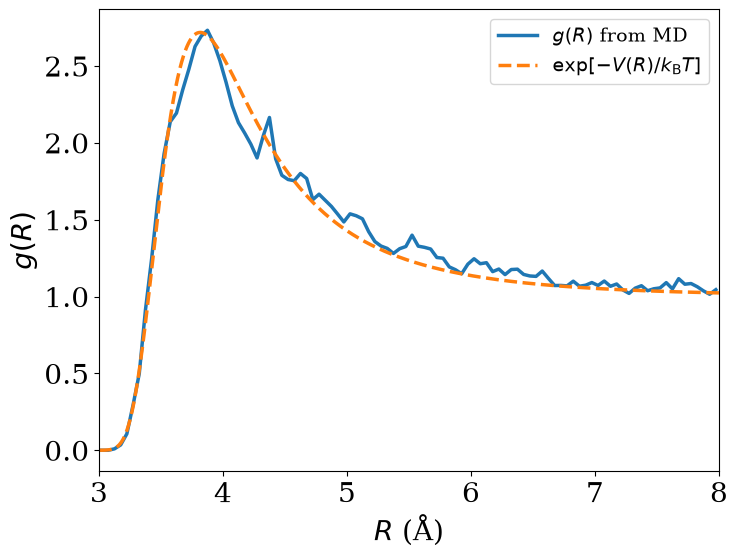

In [11]:
fig, ax = plt.subplots()
ax.plot(r, g_r, label='$g(R)$ from MD')
ax.plot(r_fine, np.exp(-pair_potential(r_fine) / temperature), '--', label=r'$\exp[-V(R)/k_\mathrm{B}T]$')
ax.set_xlabel('$R$ (Å)')
ax.set_ylabel('$g(R)$')
ax.set_xlim(3.0, cutoff)
ax.legend()
plt.show()